# INX FUTURE INC EMPLOYEE PERFORMANCE - MACHINE LEARNING MODEL TRAINING

## 1. INTRODUCTION
## 2. MACHINE LEARNING OBJECTIVE
## 3. BUSINESS PROBLEM
## 4. FEATURE SELECTION
## 5. FEATURE ENGINEERING
## 6. PREPARING DATA FOR MODELLING
## 7. TRAINING AND TESTING DATA SPLIT
## 8. DATA PREPROCESSING PIPELINE
## 9. LOGISTIC REGRESSION MODEL
## 10. SUPPORT VECTOR MACHINE MODEL
## 11. RANDOM FOREST MODEL
## 12. MODEL EVALUATION
## 13. CROSS-VALIDATION
## 14. MODEL COMPARISON
## 15. SELECTION OF THE BEST MODEL
## 16. CONFUSION MATRIX
## 17. FEATURE IMPORTANCE ANALYSIS
## 18. PERMUTATION IMPORTANCE
## 19. TOP THREE FACTORS AFFECTING EMPLOYEE PERFORMANCE
## 20. MODEL INTERPRETATION
## 21. SAVE THE FINAL MODEL
## 22. BUSINESS INSIGHT
## 23. CONCLUSION



# INX Future Inc Employee Performance - Machine Learning Model Training

## 1. INTRODUCTION

This notebook focuses on developing machine learning classification models for the INX Future Inc Employee Performance project.

The objective is to use employee-related attributes to predict the employee's PerformanceRating. Three supervised machine learning algorithms are developed and compared: Logistic Regression, Support Vector Machine, and Random Forest.

The modelling workflow includes feature selection, feature engineering, data preprocessing, training and testing data preparation, model training, evaluation, cross-validation, feature importance analysis, permutation importance, and final model persistence.

The model development process follows a reproducible machine learning pipeline so that the same preprocessing operations are consistently applied to both training and unseen data.

## 1.1 Import Required Libraries

In [47]:
# Import required libraries

import os
import warnings
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import(
train_test_split,
StratifiedKFold,
cross_validate
)

from sklearn.compose import ColumnTransformer

from sklearn.pipeline import Pipeline

from sklearn.preprocessing import(
OneHotEncoder,
StandardScaler,
OrdinalEncoder
)

from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import(
accuracy_score,
precision_score,
recall_score,
f1_score,
classification_report,
confusion_matrix
)

from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")

print("All required libraries imported successfully.")

All required libraries imported successfully.


### Insight

The required libraries for data handling, preprocessing, model training, evaluation, visualization, and model persistence have been imported successfully.

## 2. MACHINE LEARNING OBJECTIVE 

The machine learning objective is to develop classification models capable of predicting an employee's PerformanceRating using available employee-related attributes.

PerformanceRating is treated as the dependent variable, while the remaining relevant employee characteristics are considered predictor variables.

Multiple algorithms are trained so that their predictive performance can be compared using consistent evaluation metrics.

### 2.1 Define Project Paths

In [4]:
# Define project paths

project_name = r"E:\IABAC\INX_Future_Inc_Employee_Performance"

processed_path = os.path.join(
    project_name,
    "data",
    "processed"
)

processed_file = os.path.join(
    processed_path,
    "employee_performance_processed.csv"
)

print(f"Project name: {project_name}")
print(f"Processed dataset path: {processed_file}")

Project name: E:\IABAC\INX_Future_Inc_Employee_Performance
Processed dataset path: E:\IABAC\INX_Future_Inc_Employee_Performance\data\processed\employee_performance_processed.csv


### Insight

The project uses a supervised classification approach because the target variable, PerformanceRating, contains predefined employee performance categories.

## 3. BUSINESS PROBLEM

INX Future Inc wants to understand employee performance and identify factors associated with different employee performance ratings.

A machine learning model can help identify patterns in historical employee data and provide a systematic way to predict PerformanceRating for employee records.

The model should not be interpreted as proof that any particular employee characteristic causes performance. Instead, it identifies patterns learned from the available historical data.



### 3.1 Load Processed Dataset

In [5]:
# Load processed dataset

df = pd.read_csv(processed_file)

print("Processed dataset loaded successfully.")
print(f"Number of employees: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}")

Processed dataset loaded successfully.
Number of employees: 1200
Number of columns: 28


### Insight

The processed employee dataset is now available for machine learning. The target variable and predictors will be separated before training.

## 4. FEATURE SELECTION

Feature selection determines which variables will be supplied to the machine learning models.

The target variable PerformanceRating is excluded from the feature matrix because it represents the outcome to be predicted.

Identifier variables and variables that do not provide meaningful predictive information should also be excluded. The processed dataset from the previous stage has already undergone basic identifier and constant-column checks.

### 4.1 Define Target Variable



In [6]:
# Define target variable

target_column = "PerformanceRating"

print(f"Target column: {target_column}")

if target_column not in df.columns:
    raise ValueError(
        f"Target column'{target_column}' was not found in the dataset."
    )
print("Target column successfully identified.")

Target column: PerformanceRating
Target column successfully identified.


### 4.2 Separate Features and Target

In [7]:
# Separate features and target

target_column = "PerformanceRating"

X = df.drop(
    columns=["PerformanceRating", "EmpNumber", "Attrition"]
)

y = df[target_column]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (1200, 25)
y shape: (1200,)


### 4.3 Display Selected Feature Names

In [8]:
# Display selected feature names

print("Selected features:\n")

for index, column in enumerate(X.columns, start = 1):
    print(f"{index}. {column}")

Selected features:

1. Age
2. Gender
3. EducationBackground
4. MaritalStatus
5. EmpDepartment
6. EmpJobRole
7. BusinessTravelFrequency
8. DistanceFromHome
9. EmpEducationLevel
10. EmpEnvironmentSatisfaction
11. EmpHourlyRate
12. EmpJobInvolvement
13. EmpJobLevel
14. EmpJobSatisfaction
15. NumCompaniesWorked
16. OverTime
17. EmpLastSalaryHikePercent
18. EmpRelationshipSatisfaction
19. TotalWorkExperienceInYears
20. TrainingTimesLastYear
21. EmpWorkLifeBalance
22. ExperienceYearsAtThisCompany
23. ExperienceYearsInCurrentRole
24. YearsSinceLastPromotion
25. YearsWithCurrManager


### Insight

The feature matrix `X` contains the predictor variables, while `y` contains PerformanceRating. Keeping the target separate prevents target leakage during model training.

## 5. FEATURE ENGINEERING

Feature engineering involves transforming or creating variables so that machine learning algorithms can use the available information effectively.

For this project, the initial feature engineering strategy is conservation. The existing employee attributes are retained rather than creating many derived variables unnecessarily.

Categorical variables will be converted into numerical representation using One-Hot Encoding, while numerical variables will be standardized for algorithms that are sensitive to feature scale. 

### 5.1 Identify Numerical and Categorical Features

In [9]:
# Identify numerical and categorical features

numerical_features = X.select_dtypes(
    include = np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    include = ["object", "category", "bool"]
).columns.tolist()

print(f"Number of numerical features: {len(numerical_features)}\n")
print(f"Number of categorical features: {len(categorical_features)}\n")

print(f"Numerical features: {numerical_features}\n")
print(f"Categorical features: {categorical_features}")

Number of numerical features: 18

Number of categorical features: 7

Numerical features: ['Age', 'DistanceFromHome', 'EmpEducationLevel', 'EmpEnvironmentSatisfaction', 'EmpHourlyRate', 'EmpJobInvolvement', 'EmpJobLevel', 'EmpJobSatisfaction', 'NumCompaniesWorked', 'EmpLastSalaryHikePercent', 'EmpRelationshipSatisfaction', 'TotalWorkExperienceInYears', 'TrainingTimesLastYear', 'EmpWorkLifeBalance', 'ExperienceYearsAtThisCompany', 'ExperienceYearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']

Categorical features: ['Gender', 'EducationBackground', 'MaritalStatus', 'EmpDepartment', 'EmpJobRole', 'BusinessTravelFrequency', 'OverTime']


### Insight

The dataset is divided into numerical and categorical variables. This separation allows each data type to receive an appropriate treatment inside the machine learning pipeline.

## 6. PREPARING DATA FOR MODELLING

Before model training, the input data must be prepared so that all algorithms receive valid numerical input.

Numerical variables are handled using median imputation and standardization. Categorical variables are handled using the most frequent category for missing values, followed by One-Hot Encoding.

All proprocessing operations are included inside a Scikit-learn pipeline. This prevents preprocessing information from the test set from being used during training.


### 6.1 Display Missing Values in X and y

In [13]:
# Display missing values in X and y

print(
    f"Total missing values in features:"
    f"{X.isnull().sum().sum()}"
)

print(
    f"Total missing values in target:"
    f"{y.isnull().sum().sum()}"
)

Total missing values in features:0
Total missing values in target:0


### 6.2 Display Target Distribution



In [14]:
# Display target distribution

target_counts = y.value_counts().sort_index()

print("Target class distribution:")

for class_value, count in target_counts.items():
    percentage = (
        count / len(y)
    )* 100

    print(
    f"Class {class_value}:"
    f"{count} employees"
    f"({percentage:.2f}%)"
    )

Target class distribution:
Class 2:194 employees(16.17%)
Class 3:874 employees(72.83%)
Class 4:132 employees(11.00%)


### Insight 

The target-class distribution is checked before model training. This is important because differences in class frequency can influence classification metrics and the interpretation of model performance.

## 7. TRAINING AND TESTING DATA SPLIT

The dataset is divided into training and testing subsets.

The training dataset is used to learn model parameters, while the testing dataset is reserved for final evaluation on previously unseen observations.

Stratification is used so that the relative distribution of PerformanceRating classes is approximately maintained in both subsets.

### 7.1 Split Dataset Into Training and Testing Sets

In [15]:
# Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size = 0.2,
    random_state = 42,
    stratify = y
)

print(f"Training feature shape: {X_train.shape}")
print(f"Testing feature shape: {y_test.shape}")

print(f"Training target size: {y_train.shape[0]}")
print(f"Testing target size: {y_test.shape[0]}")

Training feature shape: (960, 25)
Testing feature shape: (240,)
Training target size: 960
Testing target size: 240


### 7.2 Verify Target Distribution After Split

In [16]:
# verify target distribution after split

print("Training target distribution:\n")

for value, count in y_train.value_counts().sort_index().items():

    percentage = (
        count / len (y_train)
    )* 100

    print(
        f"Class {value}:"
        f"{count}"
        f"({percentage:.2f}%)\n"
)

print("Testing target distribution:\n")

for value, count in y_test.value_counts().sort_index().items():

    percentage = (
    count / len (y_test)
)* 100

print(
    f"Class {value}:"
    f"{count}"
    f"({percentage:.2f}%)"
)



Training target distribution:

Class 2:155(16.15%)

Class 3:699(72.81%)

Class 4:106(11.04%)

Testing target distribution:

Class 4:26(10.83%)


### Insight

An `80:20` training-testing split is used. Stratification helps maintain a similar representation of the performance-rating classes in both datasets.

## 8. DATA PREPROCESSING PIPELINE

A unified preprocessing pipeline is created to ensure that the same transformations are applied consistently during model training, testing, cross-validation, and future predictions.

Numerical variables are processed using median imputation followed by StandardScaler. Categorical variables are processed using most-frequent imputation followed by OneHotEncoder.

Using a ColumnTransformer allows different preprocessing strategies to be applied to different feature types.

### 8.1 Numerical Preprocessing Pipeline

In [65]:
numerical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

### 8.2 Categorical Preprocessing Pipeline

In [71]:
# Categorical preprocessing pipeline

categorical_pipeline = Pipeline(
steps = [
    (
        "imputer",
        SimpleImputer(strategy = "most_frequent")
    ),
    (
        "encoder",
        OneHotEncoder(
            handle_unknown = "ignore"
        )
    )
    ]
)

print("Numerical preprocessing pipeline created.")
print("Categorical preprocessing pipeline created.")

Numerical preprocessing pipeline created.
Categorical preprocessing pipeline created.


### 8.3 Combine Numerical and Categorical Preprocessing

In [74]:
# Combine numerical and categorical preprocessing

preprocessor = ColumnTransformer(
    transformers = [
        (
            "numerical",
            numerical_pipeline,
            numerical_features
        ),
        (
            "categorical",
            categorical_pipeline,
            categorical_features
        )
    ],
    remainder = "drop"
)

print("Column Transformer preprocessing pipeline created.")

Column Transformer preprocessing pipeline created.


### Insight

The preprocessing pipeline ensures that the transformation is learned only from the training data within each model-fitting process. This reduces the risk of the leakage and makes the workflow reproducible.

## 9. LOGISTIC REGRESSION MODEL

Logistic Regression is a linear classification algorithm that estimates the probability of observations belonging to different classes.

Although the algorithm is relatively simple, it provides an important baseline model and can provide interpretable coefficients after categorical variables have been encoded.

The preprocessing pipeline is combined with Logistic Regression so that raw numerical and categorical data can be supplied directly to the model.

### 9.1 Create Logistic Regression Pipeline

In [20]:
# Create Logistic Regression pipeline

logistic_model = Pipeline(
    steps = [
        (
        "preprocessor",
        preprocessor
        ),
        (
            "classifier",
            LogisticRegression(
                max_iter = 2000,
                random_state = 42
            )
        )
    ]
)

print("Logistic Regression pipeline created.")

Logistic Regression pipeline created.


### 9.2 Train Logistic Regression


In [21]:
# Train Logistic Regression

logistic_model.fit(
    X_train,
    y_train
)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


### Insight

Logistic Regression provides a baseline classification model against which the other algorithms can be compared.

## 10. SUPPORT VECTOR MACHINE MODEL

Support Vector Machine (SVM) is a supervised classification algorithm that attempts to identify decision boundaries that separate classes effectively.

SVM can work well when the classes are separable in a transformed feature space. Feature scaling is particularly important for SVM, which is one reason StandardScaler is included in the preprocessed pipeline.

### 10.1 Create Support Vector Pipeline

In [22]:
# Create Support Vector Pipeline

svm_model = Pipeline(
    steps = [
        (
            "preprocessor",
            preprocessor
        ),
        (
            "classifier",
            SVC(
                kernel = "rbf",
                random_state = 42
            )
        )
    ]
)

print("Support Vector Machine pipeline created.")


Support Vector Machine pipeline created.


### 10.2 Train SVM

In [23]:
# Train SVM

svm_model.fit(
    X_train,
    y_train
)

print("Support Vector Machine model trained successfully.")

Support Vector Machine model trained successfully.


### Insight

The SVM model has been trained using the same preprocessing strategy as Logistic Regression, making the model comparison more consistent.

## 11. RANDOM FOREST MODEL

Random Forest is an ensemble learning algorithm that combines multiple decision trees to make predictions.

Random Forest can capture nonlinear relationships and interactions between variables. Unlike Logistic Regression and SVM, feature scaling is not required by the underlying tree-based algorithm, but the same preprocessing framework is retained so the workflow remains consistent.

### 11.1 Create Random Forest Pipeline

In [31]:
# Create Random Forest pipeline

random_forest_model = Pipeline(
    steps = [
        (
            "preprocessor",
            preprocessor
        ),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators = 300,
                random_state = 42,
                n_jobs = -1
            )
        )
    ]
)

print("Random Forest pipeline created.")

Random Forest pipeline created.


### 11.2 Train Random Forest

In [32]:
# Train Random Forest

random_forest_model.fit(
    X_train,
    y_train
)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


### Insight

Random Forest provides a nonlinear ensemble model that can capture complex realtionships among employee characteristics.

## 12. MODEL EVALUATION

The trained models are evaluated using the testing dataset.

The following metrics are calculated:

- Accuracy
- Weighted Precision
- Weighted Recall
- Weighted F1-score

Weighted metrics are used because they account for the number of observations in each class.

### 12.1 Store Trained Models

In [33]:
# Store trained models

models = {
    "Logistic Regression": logistic_model,
    "Support Vector Machine": svm_model,
    "Random Forest": random_forest_model
}

print(f"Number of trained models: {len(models)}")

for model_name in models:
    print(f"- {model_name}")

Number of trained models: 3
- Logistic Regression
- Support Vector Machine
- Random Forest


### 12.2 Evaluate Models

In [34]:
# Evaluate models

evaluation_results = []

for model_name, model in models.items():
    y_pred = model.predict(X_test)

    accuracy = accuracy_score(
    y_test,
    y_pred
    )

    precision = precision_score(
    y_test,
    y_pred,
    average = "weighted",
    zero_division = 0
    )

    recall = recall_score(
    y_test,
    y_pred,
    average = "weighted",
    zero_division = 0
    )

    f1 = f1_score(
    y_test,
    y_pred,
    average = "weighted",
    zero_division = 0
    )

    evaluation_results.append({
    "Model": model_name,
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1_Score": f1
    })

    print(
    f"{model_name}:"
    f"Accuracy = {accuracy:.4f},"
    f"Precision = {precision:.4f},"
    f"Recall = {recall:.4f},"
    f"F1 = {f1:.4f}"
    )

    evaluation_df = pd.DataFrame(
    evaluation_results
    )

    display(evaluation_results)

Logistic Regression:Accuracy = 0.8208,Precision = 0.8127,Recall = 0.8208,F1 = 0.8130


[{'Model': 'Logistic Regression',
  'Accuracy': 0.8208333333333333,
  'Precision': 0.8127124451754386,
  'Recall': 0.8208333333333333,
  'F1_Score': 0.813047329561414}]

Support Vector Machine:Accuracy = 0.8250,Precision = 0.8328,Recall = 0.8250,F1 = 0.8015


[{'Model': 'Logistic Regression',
  'Accuracy': 0.8208333333333333,
  'Precision': 0.8127124451754386,
  'Recall': 0.8208333333333333,
  'F1_Score': 0.813047329561414},
 {'Model': 'Support Vector Machine',
  'Accuracy': 0.825,
  'Precision': 0.8328304048892284,
  'Recall': 0.825,
  'F1_Score': 0.8014676339285713}]

Random Forest:Accuracy = 0.9167,Precision = 0.9196,Recall = 0.9167,F1 = 0.9132


[{'Model': 'Logistic Regression',
  'Accuracy': 0.8208333333333333,
  'Precision': 0.8127124451754386,
  'Recall': 0.8208333333333333,
  'F1_Score': 0.813047329561414},
 {'Model': 'Support Vector Machine',
  'Accuracy': 0.825,
  'Precision': 0.8328304048892284,
  'Recall': 0.825,
  'F1_Score': 0.8014676339285713},
 {'Model': 'Random Forest',
  'Accuracy': 0.9166666666666666,
  'Precision': 0.9196408529741862,
  'Recall': 0.9166666666666666,
  'F1_Score': 0.9131555944055945}]

### 12.3 Classification Reports - Generate Classification Reports

In [35]:
# Generate classification reports

for model_name, model in models.items():
    y_pred = model.predict(X_test)

    print("=" *70)
    print(f"Classification Report: {model_name}")
    print("=" *70)

    print(
    classification_report(
    y_test,
    y_pred,
    zero_division = 0
    )
    )

Classification Report: Logistic Regression
              precision    recall  f1-score   support

           2       0.59      0.49      0.54        39
           3       0.86      0.93      0.89       175
           4       0.84      0.62      0.71        26

    accuracy                           0.82       240
   macro avg       0.76      0.68      0.71       240
weighted avg       0.81      0.82      0.81       240

Classification Report: Support Vector Machine
              precision    recall  f1-score   support

           2       0.88      0.38      0.54        39
           3       0.82      0.98      0.89       175
           4       0.86      0.46      0.60        26

    accuracy                           0.82       240
   macro avg       0.85      0.61      0.68       240
weighted avg       0.83      0.82      0.80       240

Classification Report: Random Forest
              precision    recall  f1-score   support

           2       0.91      0.77      0.83        39
   

### Insight

The test-set evaluation provides a direct comparison of how the three trained models perform on unseen data. Accuracy provides overall correctness, while precision, recall, and F1-score provide additional information about classification performance across the target classes.

## 13. CROSS-VALIDATION

A single train-test split can produce results that depend on the particular observation assigned to the testing set.

Stratified K-Fold cross-validation provides a more robust estimate by repeatedly training and evaluating each model on different subsets of the training data while maintaining the target-class distribution. 

Five-fold cross-validation is used in this project.


### 13.1 Create Stratified K-Fold Cross-Validation

In [36]:
# Create Stratified K-Fold cross-validation

cv = StratifiedKFold(
    n_splits = 5,
    shuffle = True,
    random_state = 42
)

print(f"Cross-validation folds: {cv.n_splits}")
print("Stratified cross-validation enabled.")

Cross-validation folds: 5
Stratified cross-validation enabled.


### 13.2 Cross-Validation Scoring Metrics

In [30]:
# Cross-validation scoring metrics

scoring ={
    "accuracy": "accuracy",
    "precision": "precision_weighted",
    "recall": "recall_weighted",
    "f1": "f1_weighted"
}

cv_results = []

for model_name, model in models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv = cv,
        scoring = scoring,
        n_jobs = -1
    )

    cv_results.append({
    "Model": model_name,
    "CV_Accuracy_Mean": scores["test_accuracy"].mean(),
    "CV_Precision_Mean": scores["test_precision"].mean(),
    "CV_Recall_Mean": scores["test_f1"].mean(),
    "CV_F1_STD": scores["test_f1"].std()
    })

    print(
    f"{model_name}:"
    f"CV Accuracy = {scores['test_accuracy'].mean():.4f},"
    f"CV F1 = {scores['test_f1'].mean():.4f}"
    )

    cv_df = pd.DataFrame(cv_results)
    display(cv_df)

Logistic Regression:CV Accuracy = 0.8052,CV F1 = 0.8009


,Model,CV_Accuracy_Mean,CV_Precision_Mean,CV_Recall_Mean,CV_F1_STD
0,Logistic Regression,0.805208,0.800273,0.800911,0.017516


Support Vector Machine:CV Accuracy = 0.7938,CV F1 = 0.7616


,Model,CV_Accuracy_Mean,CV_Precision_Mean,CV_Recall_Mean,CV_F1_STD
0,Logistic Regression,0.805208,0.800273,0.800911,0.017516
1,Support Vector Machine,0.793750,0.795600,0.761551,0.027464


Random Forest:CV Accuracy = 0.9094,CV F1 = 0.9053


,Model,CV_Accuracy_Mean,CV_Precision_Mean,CV_Recall_Mean,CV_F1_STD
0,Logistic Regression,0.805208,0.800273,0.800911,0.017516
1,Support Vector Machine,0.793750,0.795600,0.761551,0.027464
2,Random Forest,0.909375,0.911210,0.905268,0.008486


### Insight

Cross-validation provides multiple estimates of the model performance instead of relying on a single training-validation configuration. The mean and standard deviation of the F1-score help assess both average performance and variation across folds.

## 14. MODEL COMPARISON

The three models are compared using both test-set performance and cross-validation performance.

Accuracy, precision, recall, and F1-score are considered together. F1-score is used as the primary comparison metric because it balances precision and recall.

No model is assumed to be superior before examining the actual evaluation results.

### 14.1 Sort Models By Test-Set F1 Score


In [37]:
# Sort models by test-set F1 score

comparison_df = evaluation_df.sort_values(
    by = "F1_Score",
    ascending = False
).reset_index(drop = True)

print("Model comparison based on test weighted F1-score:\n")
display(comparison_df)

Model comparison based on test weighted F1-score:



,Model,Accuracy,Precision,Recall,F1_Score
0,Random Forest,0.916667,0.919641,0.916667,0.913156
1,Logistic Regression,0.820833,0.812712,0.820833,0.813047
2,Support Vector Machine,0.825000,0.832830,0.825000,0.801468


### 14.2 Display Cross-Validation Comparison



In [40]:
# Display cross-validation comparison

cv_comparison = cv_df.sort_values(
    by = "CV_F1_STD",
    ascending = False
).reset_index(drop = True)

print("Model comparison based on cross-validation weighted F1-score:\n")

display(cv_comparison)

Model comparison based on cross-validation weighted F1-score:



,Model,CV_Accuracy_Mean,CV_Precision_Mean,CV_Recall_Mean,CV_F1_STD
0,Support Vector Machine,0.793750,0.795600,0.761551,0.027464
1,Logistic Regression,0.805208,0.800273,0.800911,0.017516
2,Random Forest,0.909375,0.911210,0.905268,0.008486


### 14.3 Visualization - Compare Test-Set Metrics

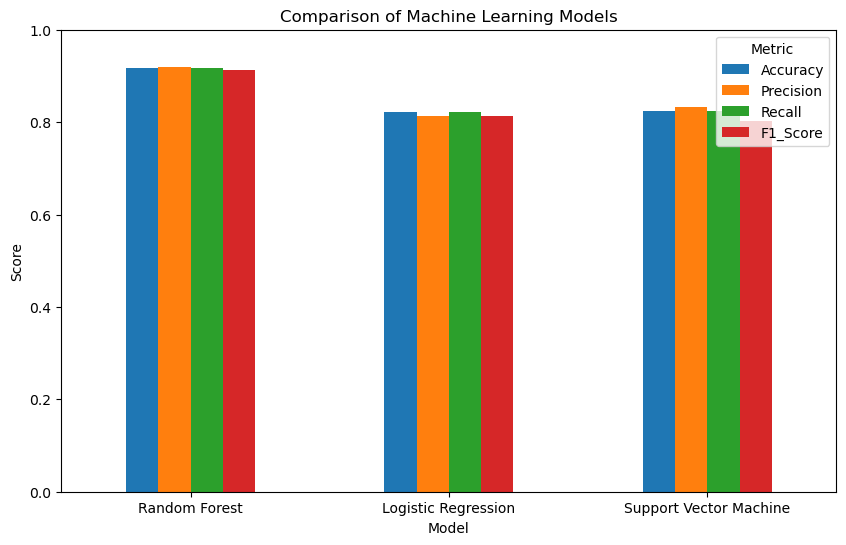

In [45]:
# Compare test-set metrics

metrics_to_plot = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1_Score"
]

plot_data = comparison_df.set_index(
    "Model"
)[metrics_to_plot]

plot_data.plot(
    kind = "bar",
    figsize = (10,6)
)

plt.title(
    "Comparison of Machine Learning Models"
)

plt.xlabel("Model")
plt.ylabel("Score")

plt.xticks(rotation = 0)
plt.ylim(0, 1)
plt.legend(
    title = "Metric"
)

plt.show()

### Insight

The comparison table provides an objective view of the three models. The final model should be selected after considering both test-set performance and cross-validation results rather than relying on a single metric alone.

## 15. SELECTION OF THE BEST MODEL

For this project, the model selection criterion is the weighted F1-score on the held-out test dataset.

Select the model with the highest test weighted F1-score as the final candidate model. Cross-validation results are also reviewed to understand whether the model demonstrates reasonably consistent performance across different training folds.

This selection is data-driven and should be reported together with the actual evaluation metrics.

### 15.1 Select Model Based on Test Weighted F1-Score

In [79]:
# Select model based on test weighted F1-score

best_model_name = comparison_df.iloc[0]["Model"]

best_model = models[best_model_name]

best_test_f1 = comparison_df.iloc[0]["F1_Score"]

print(f"Selected model: {best_model_name}")
print(f"Selected model test F1-Score: {best_test_f1:.4f}")

Selected model: Random Forest
Selected model test F1-Score: 0.9132


### 15.2 Display Selected Model's Complete Test Metrics

In [81]:
# Display selected model's complete test metrics

selected_metrics = comparison_df[
    comparison_df["Model"] == best_model_name
    ]
display(selected_metrics)

,Model,Accuracy,Precision,Recall,F1_Score
0,Random Forest,0.916667,0.919641,0.916667,0.913156


### Insight

The model with the highest weighted F1-score on the held-out test set is selected as the candidate final model. The actual model name and score are generated automatically from the dataset rather than being predetermined.

## 16. CONFUSION MATRIX

A confusion matrix provides a detailed view of classification results by showing the actual classes against the predicted classes.

The diagonal values represent correctly classified observations, while off-diagonal values represent classification errors.

The confusion matrix is particularly useful for understanding which PerformanceRating categories are being confused by the selected model.

### 16.1 Generate Predictions Using Selected Model

In [84]:
# Generate predictions using selected model

y_pred_best = best_model.predict(
    X_test
)

print(f"Predictions geenrated using:{best_model_name}")
print(f"Number of predictions: {len(y_pred_best)}")

Predictions geenrated using:Random Forest
Number of predictions: 240


### 16.2 Calculate Confusion Matrix



In [85]:
cm = confusion_matrix(
    y_test,
    y_pred_best
)

print("Confusion Matrix:\n")
print(cm)

Confusion Matrix:

[[ 30   9   0]
 [  3 172   0]
 [  0   8  18]]


### 16.3 Visualization - Plot Confusion matrix

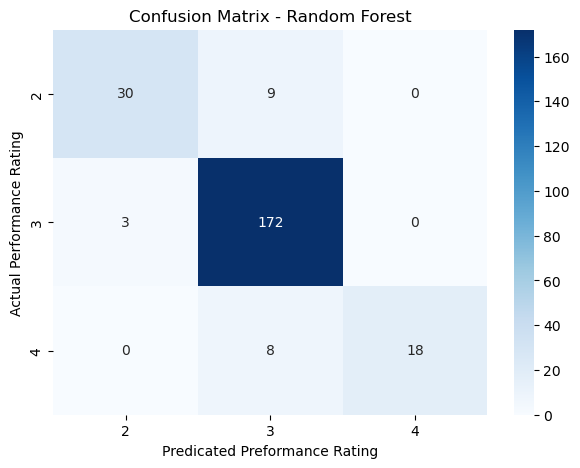

In [89]:
# Plot confusion matrix

plt.figure(figsize = (7,5))

sns.heatmap(
    cm,
    annot = True,
    fmt = "d",
    cmap = "Blues",
    xticklabels = sorted(y_test.unique()),
    yticklabels = sorted(y_test.unique())
)

plt.title(
    f"Confusion Matrix - {best_model_name}"
)

plt.xlabel("Predicated Preformance Rating")
plt.ylabel("Actual Performance Rating")
plt.show()

### Insight

The confusion matrix shows which performance-rating classes are predicted correctly and where misclassifications occur. This provides more detail than overall accuracy alone.

## 17. FEATURE IMPORTANCE ANALYSIS

Feature importance analysis identifies variables that contribute strongly to predictions made by the selected model.

For tree-based models such as Random Forest, built-in feature importance can be extracted directly. For models that do not provide the same tree-based importance measure, permutation importance can be used instead.

The transformed feature names are extracted from the preprocessing pipeline so the encoded categorical variables can also be examined.

### 17.1 Check Whether Selected Model Contains Random Forest



In [93]:
# Check whether selected model contains random forest

selected_classifier = best_model.named_steps["classifier"]

print(
    f"Selected classifier type:\n"
    f"{type(selected_classifier).__name__}"
)

Selected classifier type:
RandomForestClassifier


### 17.2 Extract Transformed Feature Names

In [95]:
# Extract transformed feature names

fitted_preprocessor = best_model.named_steps[
    "preprocessor"
    ]

feature_names = (
    fitted_preprocessor
    .get_feature_names_out()
)

print(
    f"Number of transformed features:"
    f"{len(feature_names)}"
)

print("First transformed features:")

for index, feature in enumerate(
    feature_names[:20],
    start = 1
):
    print(f"{index}. {feature}")

Number of transformed features:59
First transformed features:
1. numerical__Age
2. numerical__DistanceFromHome
3. numerical__EmpEducationLevel
4. numerical__EmpEnvironmentSatisfaction
5. numerical__EmpHourlyRate
6. numerical__EmpJobInvolvement
7. numerical__EmpJobLevel
8. numerical__EmpJobSatisfaction
9. numerical__NumCompaniesWorked
10. numerical__EmpLastSalaryHikePercent
11. numerical__EmpRelationshipSatisfaction
12. numerical__TotalWorkExperienceInYears
13. numerical__TrainingTimesLastYear
14. numerical__EmpWorkLifeBalance
15. numerical__ExperienceYearsAtThisCompany
16. numerical__ExperienceYearsInCurrentRole
17. numerical__YearsSinceLastPromotion
18. numerical__YearsWithCurrManager
19. categorical__Gender_Female
20. categorical__Gender_Male


### 17.3 Built-in Feature Importance For Tree-Based Selected Model

In [99]:
# Built-in feature importance for tree-based selected model

if hasattr(
    selected_classifier,
    "feature_importances_"
):

    importance_values = (
        selected_classifier
        .feature_importances_
    )

    feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
    }).sort_values(
    by = "Importance",
    ascending = False
    )

    print(
    f"Number of feature importance values:"
    f"{len(importance_values)}"
    )

    display(feature_importance_df.head(20)
           )

else:
    feature_imporatnce_df = None

    print(
        f"{best_maode_name} does not provide"
        f" built-in tree feature importance."
)
    

Number of feature importance values:59


,Feature,Importance
9,numerical__EmpLastSalaryHikePercent,0.174782
3,numerical__EmpEnvironmentSatisfaction,0.172061
16,numerical__YearsSinceLastPromotion,0.078587
4,numerical__EmpHourlyRate,0.039331
15,numerical__ExperienceYearsInCurrentRole,0.035997
0,numerical__Age,0.035309
14,numerical__ExperienceYearsAtThisCompany,0.033828
17,numerical__YearsWithCurrManager,0.032683
1,numerical__DistanceFromHome,0.030471
11,numerical__TotalWorkExperienceInYears,0.029825


### 17.4 Visualize Built-in Feature Importance 

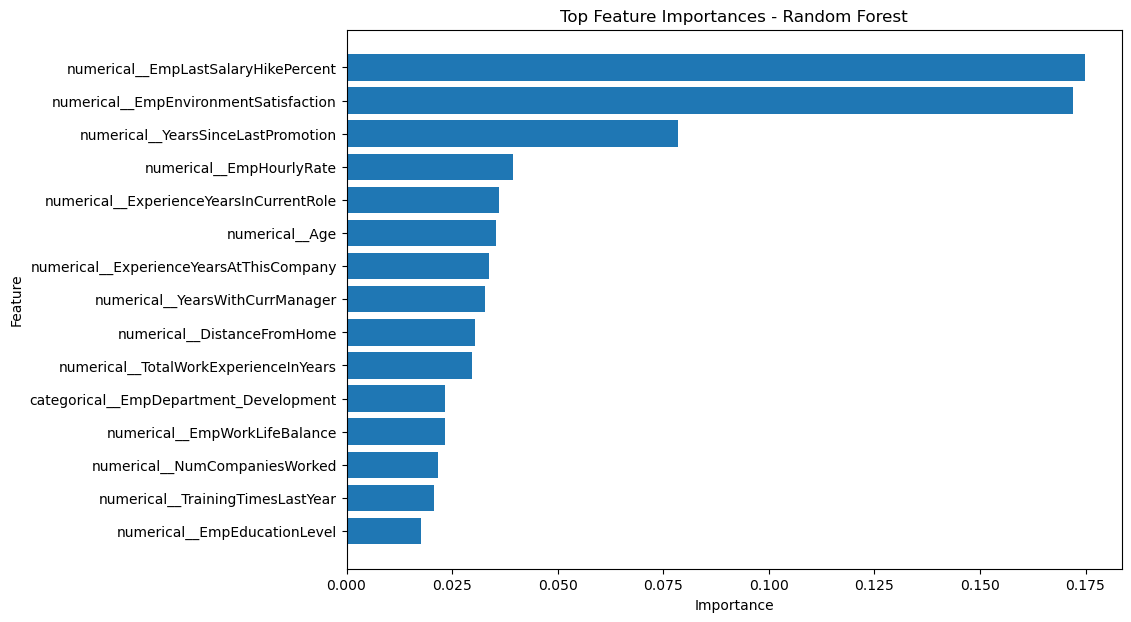

In [100]:
# Visualize built-in feature importance if available

if feature_importance_df is not None:

    top_features = (
        feature_importance_df
        .head(15)
        .sort_values(
            "Importance"
        )
    )

    plt.figure(figsize=(10, 7))

    plt.barh(
        top_features["Feature"],
        top_features["Importance"]
    )

    plt.title(
        f"Top Feature Importances - {best_model_name}"
    )

    plt.xlabel("Importance")
    plt.ylabel("Feature")

    plt.show()


### Insight

Feature importance identifies variables that contribute strongly to predictions according to the selected model's internal importance mechanism. Importance is model-dependent and should not automatically be interpreted as causal influence


## 18. PERMUTATION IMPORTANCE

Permutation importance measures the decrease in model performance when the values of a feature are randomly shuffled.

If shuffling a feature causes a meaningful reduction in model performance, that feature contains information that the model relies on for prediction.

Permutation importance is calculated on the held-out test dataset so that feature relevance is evaluated on unseen observations.


### 18.1 Calculate Permutation Importance



In [102]:
# Calculate permutation importance


n_repeats = 10


permutation_result = permutation_importance(
    best_model,
    X_test,
    y_test,
    n_repeats=n_repeats,
    random_state=42,
    scoring="accuracy",
    n_jobs=-1
)

print(
    f"Permutation importance calculated "
    f"using {n_repeats} repetitions."
)

Permutation importance calculated using 10 repetitions.


### 18.2 Create Permutation Importance DataFrame

In [103]:
# Create permutation importance DataFrame

permutation_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance_Mean": permutation_result.importances_mean,
    "Importance_STD": permutation_result.importances_std
}).sort_values(
    by="Importance_Mean",
    ascending=False
)

print("Permutation importance results:")

display(
    permutation_df.head(20)
)


Permutation importance results:


,Feature,Importance_Mean,Importance_STD
9,EmpEnvironmentSatisfaction,0.206667,0.020344
16,EmpLastSalaryHikePercent,0.130000,0.016646
23,YearsSinceLastPromotion,0.047917,0.012395
4,EmpDepartment,0.040000,0.013202
22,ExperienceYearsInCurrentRole,0.019583,0.010712
5,EmpJobRole,0.011667,0.006667
20,EmpWorkLifeBalance,0.003750,0.003931
21,ExperienceYearsAtThisCompany,0.002083,0.004658
1,Gender,0.000833,0.003118
6,BusinessTravelFrequency,-0.001250,0.001909


### 18.3 Visualize - Plot Top Permutation Importance

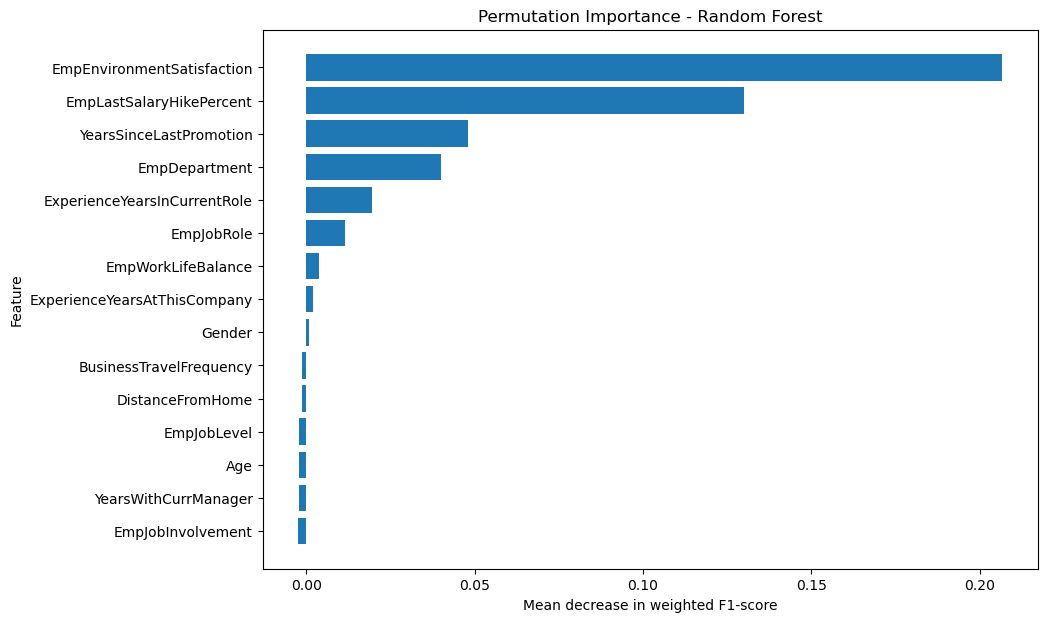

In [104]:
# Plot top permutation importance

top_permutation = (
    permutation_df
    .head(15)
    .sort_values(
        "Importance_Mean"
    )
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_permutation["Feature"],
    top_permutation["Importance_Mean"]
)

plt.title(
    f"Permutation Importance - {best_model_name}"
)

plt.xlabel(
    "Mean decrease in weighted F1-score"
)

plt.ylabel("Feature")

plt.show()


### Insight

Permutation importance provides a model-agnostic view of feature relevance. The results indicate which original input variables have the greatest effect on the selected model's predictive performance when their information is disrupted.


## 19. TOP THREE FACTORS AFFECTING EMPLOYEE PERFORMANCE

The three highest-ranked variables from permutation importance are identified as the top factors associated with the selected model's predictive performance.

These should be described as important predictive factors or model-associated factors rather than causal factors. Machine learning feature importance does not by itself establish that changing a factor will cause employee performance to change.


### 19.1 Identify Top Three Factors

In [105]:
# Identify top three factors

top_three_factors = (
    permutation_df
    .head(3)
    .copy()
)

print("Top three model-associated factors:")

for index, row in top_three_factors.iterrows():

    print(
        f"{row['Feature']}: "
        f"Permutation importance = "
        f"{row['Importance_Mean']:.6f}"
    )


Top three model-associated factors:
EmpEnvironmentSatisfaction: Permutation importance = 0.206667
EmpLastSalaryHikePercent: Permutation importance = 0.130000
YearsSinceLastPromotion: Permutation importance = 0.047917


### 19.2 Display Top Three Factors as a Table


In [106]:
# Display top three factors as a table

top_three_display = top_three_factors[
    [
        "Feature",
        "Importance_Mean",
        "Importance_STD"
    ]
].reset_index(drop=True)

top_three_display.index = (
    top_three_display.index + 1
)

display(top_three_display)


,Feature,Importance_Mean,Importance_STD
1,EmpEnvironmentSatisfaction,0.206667,0.020344
2,EmpLastSalaryHikePercent,0.130000,0.016646
3,YearsSinceLastPromotion,0.047917,0.012395


### Insight

The top three factors are determined directly from permutation importance on the test dataset. They represent variables that the selected model relies on most strongly among the available features.

They should not be interpreted as proven causes of employee performance.


## 20 MODEL INTERPRETATION

Model interpretation combines predictive performance with feature-level analysis.

The selected model provides predictions of PerformanceRating, while permutation importance provides information about which input variables are most associated with those predictions.

The interpretation should consider both the strengths and limitations of the model. High predictive performance does not imply causality, and feature importance can be affected by correlations among variables.


### 20.1 Display Final Model Interpretation Summary

In [107]:
# Display final model interpretation summary

selected_row = comparison_df[
    comparison_df["Model"] == best_model_name
].iloc[0]

print("=" * 70)
print("FINAL MODEL INTERPRETATION")
print("=" * 70)

print(f"Selected model       : {best_model_name}")
print(
    f"Test Accuracy        : "
    f"{selected_row['Accuracy']:.4f}"
)
print(
    f"Test Precision       : "
    f"{selected_row['Precision']:.4f}"
)
print(
    f"Test Recall          : "
    f"{selected_row['Recall']:.4f}"
)
print(
    f"Test F1-score        : "
    f"{selected_row['F1_Score']:.4f}"
)

print("\nTop three model-associated factors:")

for rank, row in top_three_factors.reset_index(
    drop=True
).iterrows():

    print(
        f"{rank + 1}. "
        f"{row['Feature']} "
        f"({row['Importance_Mean']:.6f})"
    )

print("=" * 70)


FINAL MODEL INTERPRETATION
Selected model       : Random Forest
Test Accuracy        : 0.9167
Test Precision       : 0.9196
Test Recall          : 0.9167
Test F1-score        : 0.9132

Top three model-associated factors:
1. EmpEnvironmentSatisfaction (0.206667)
2. EmpLastSalaryHikePercent (0.130000)
3. YearsSinceLastPromotion (0.047917)


### Insight

The selected model combines predictive performance with feature-level interpretation. The model can identify patterns in employee data, while permutation importance helps explain which available variables are most relevant to those predictions.


## 21. SAVE THE FINAL MODEL

The selected machine learning pipeline is saved using Joblib.

Because the preprocessing operations are included within the Scikit-learn pipeline, the saved object contains both the preprocessing steps and the trained classifier.

This allows the same preprocessing transformations to be applied automatically when new employee data is passed to the model.


### 21.1 Create Model Directory

In [108]:
# Create model directory

model_path = os.path.join(
    project_name,
    "src",
    "models"
)

os.makedirs(
    model_path,
    exist_ok=True
)

print(f"Model directory: {model_path}")


Model directory: E:\IABAC\INX_Future_Inc_Employee_Performance\src\models


### 21.2 Save Final Model

In [109]:
# Save final model

model_file = os.path.join(
    model_path,
    "employee_performance_model.joblib"
)

joblib.dump(
    best_model,
    model_file
)

print("Final model saved successfully.")
print(f"Model path: {model_file}")


Final model saved successfully.
Model path: E:\IABAC\INX_Future_Inc_Employee_Performance\src\models\employee_performance_model.joblib


### 21.3 Save Metadata - Save Model Metadata

In [110]:
# Save model metadata

model_metadata = {
    "project": project_name,
    "target_variable": target_column,
    "selected_model": best_model_name,
    "test_accuracy": float(selected_row["Accuracy"]),
    "test_precision": float(selected_row["Precision"]),
    "test_recall": float(selected_row["Recall"]),
    "test_f1_score": float(selected_row["F1_Score"]),
    "top_three_factors": top_three_factors[
        "Feature"
    ].tolist()
}

metadata_file = os.path.join(
    model_path,
    "model_metadata.joblib"
)

joblib.dump(
    model_metadata,
    metadata_file
)

print("Model metadata saved successfully.")
print(f"Metadata path: {metadata_file}")


Model metadata saved successfully.
Metadata path: E:\IABAC\INX_Future_Inc_Employee_Performance\src\models\model_metadata.joblib


### 21.4 Verify Model - Verify Saved Model

In [111]:
# Verify saved model

if os.path.exists(model_file):

    model_size_kb = (
        os.path.getsize(model_file)
        / 1024
    )

    print("Model file verification successful.")
    print(f"Model file: {model_file}")
    print(f"Model size: {model_size_kb:.2f} KB")

else:

    print("ERROR: Model file was not created.")


Model file verification successful.
Model file: E:\IABAC\INX_Future_Inc_Employee_Performance\src\models\employee_performance_model.joblib
Model size: 7696.30 KB


Insight
### Insight

The complete machine learning pipeline has been saved. Because preprocessing and the classifier are stored together, the saved model can later be loaded by `predict_model.ipynb` for predictions on new employee records.



## 22. BUSINESS INSIGHTS

The machine learning analysis provides business-oriented information about employee performance patterns.

The selected model identifies patterns that can be used to predict PerformanceRating based on historical employee attributes. The permutation-importance analysis identifies the three variables that the selected model relies on most strongly.

These findings should be used as analytical evidence for further investigation rather than as proof of causal relationships. Business decisions should consider organizational context and additional evidence beyond the machine learning model.


### 22.1 Geenrate Business-oriented Model Summary

In [112]:
# Generate business-oriented model summary

print("=" * 70)
print("BUSINESS INSIGHTS FROM MACHINE LEARNING")
print("=" * 70)

print(
    f"Employees analyzed       : {len(df)}"
)

print(
    f"Target variable          : {target_column}"
)

print(
    f"Selected model           : {best_model_name}"
)

print(
    f"Test weighted F1-score   : "
    f"{selected_row['F1_Score']:.4f}"
)

print(
    f"Test accuracy            : "
    f"{selected_row['Accuracy']:.4f}"
)

print("\nTop three model-associated factors:")

for rank, feature in enumerate(
    top_three_factors["Feature"],
    start=1
):

    print(
        f"{rank}. {feature}"
    )

print("=" * 70)


BUSINESS INSIGHTS FROM MACHINE LEARNING
Employees analyzed       : 1200
Target variable          : PerformanceRating
Selected model           : Random Forest
Test weighted F1-score   : 0.9132
Test accuracy            : 0.9167

Top three model-associated factors:
1. EmpEnvironmentSatisfaction
2. EmpLastSalaryHikePercent
3. YearsSinceLastPromotion


### 22.2 Business Interpretation

The analysis can support INX Future Inc in several areas:

1. Understanding patterns associated with employee performance.
2. Identifying employee attributes that the model relies on for prediction.
3. Supporting further investigation of employee satisfaction and workplace factors.
4. Understanding performance differences across employee groups.
5. Providing a predictive framework for future employee-performance analysis.

The results should be interpreted alongside HR policies, employee feedback, organizational context, and other relevant evidence.


### Insight

The machine learning model provides a quantitative method for identifying patterns associated with employee performance. The results can support further HR analysis, but model-derived associations should not be treated as causal conclusions.


## 23. CONCLUSION

The machine learning stage of the INX Future Inc Employee Performance project has been completed.

The processed employee dataset was separated into predictor variables and the PerformanceRating target variable. Numerical and categorical variables were handled using a reproducible preprocessing pipeline. The dataset was divided into training and testing subsets using stratified sampling.

Three classification algorithms were trained:

- Logistic Regression
- Support Vector Machine
- Random Forest

The models were evaluated using accuracy, precision, recall, and weighted F1-score. Five-fold stratified cross-validation was also performed to obtain additional evidence of model performance.

The final candidate model was selected based on the highest weighted F1-score on the held-out test dataset. A confusion matrix was generated to examine classification errors, while feature importance and permutation importance were used to investigate model-associated factors.

The selected model and its metadata were saved using Joblib and can be loaded in the `predict_model.ipynb` notebook.

The next stage is to use the saved model to make predictions on new employee records and demonstrate the complete prediction workflow.


### 23.1 Final Machine Learning Summary

In [113]:
# Final machine learning summary

print("=" * 75)
print("INX FUTURE INC EMPLOYEE PERFORMANCE")
print("MACHINE LEARNING MODEL TRAINING COMPLETED")
print("=" * 75)

print(f"Dataset size               : {df.shape}")
print(f"Target variable            : {target_column}")

print(
    f"Training records           : "
    f"{len(X_train)}"
)

print(
    f"Testing records            : "
    f"{len(X_test)}"
)

print(
    f"Models trained             : "
    f"{len(models)}"
)

print(
    f"Selected model             : "
    f"{best_model_name}"
)

print(
    f"Test Accuracy              : "
    f"{selected_row['Accuracy']:.4f}"
)

print(
    f"Test Precision             : "
    f"{selected_row['Precision']:.4f}"
)

print(
    f"Test Recall                : "
    f"{selected_row['Recall']:.4f}"
)

print(
    f"Test Weighted F1-score     : "
    f"{selected_row['F1_Score']:.4f}"
)

print(
    f"Final model saved at       : "
    f"{model_file}"
)

print(
    f"Model metadata saved at    : "
    f"{metadata_file}"
)

print("\nTop 3 model-associated factors:")

for rank, feature in enumerate(
    top_three_factors["Feature"],
    start=1
):

    print(
        f"{rank}. {feature}"
    )

print("=" * 75)
print("MODEL TRAINING AND EVALUATION COMPLETED SUCCESSFULLY.")
print("=" * 75)

print("\nNext Step:")

print("-" *70)
print("Predict the Model.")

print("-" * 70)



INX FUTURE INC EMPLOYEE PERFORMANCE
MACHINE LEARNING MODEL TRAINING COMPLETED
Dataset size               : (1200, 28)
Target variable            : PerformanceRating
Training records           : 960
Testing records            : 240
Models trained             : 3
Selected model             : Random Forest
Test Accuracy              : 0.9167
Test Precision             : 0.9196
Test Recall                : 0.9167
Test Weighted F1-score     : 0.9132
Final model saved at       : E:\IABAC\INX_Future_Inc_Employee_Performance\src\models\employee_performance_model.joblib
Model metadata saved at    : E:\IABAC\INX_Future_Inc_Employee_Performance\src\models\model_metadata.joblib

Top 3 model-associated factors:
1. EmpEnvironmentSatisfaction
2. EmpLastSalaryHikePercent
3. YearsSinceLastPromotion
MODEL TRAINING AND EVALUATION COMPLETED SUCCESSFULLY.

Next Step:
----------------------------------------------------------------------
Predict the Model.
---------------------------------------------------